# 08 · Final check on the locked test set (Nov 15)

Every choice so far was made by looking at the validation day (Nov 14). Choices tuned on one day can look better there than they really are, so this notebook runs **everything frozen** on a day we never looked at: **Nov 15** (`MINDsmall_test`).

**Frozen settings (nothing below is tuned):**

| Part | Setting |
|---|---|
| Finder | two-tower model from notebook 05 + 0.05 × trending, top 100 per bucket |
| Arranger | strictness 0.5 |
| Balancer | head start (feed click model fitted on Nov 9–13) + PID kp 0.5, ki 0.05, max push 0.2 |
| Simulator | 2,000 users × 30 pages, Balanced target, mood shift 0.5, 5 runs |

The only thing fitted on Nov 15 is the simulator's "truth" click model. It describes how Nov 15 users behave (the world we test in), not a setting of OwnFeed.

**About the test day:** 73K page views from 50K users, 88% of whom never appear in Nov 9–14 (they still come with a click history), and 14K articles that never appear in the train folder.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.arranger import PAGE_SIZE, arrange, mix_to_slots, normalize_scores
from src.balancer import PIDBalancer, feedforward_mix
from src.data import BUCKETS, TEST_DIR, TRAIN_DIR, explode_impressions, load_behaviors, load_news, split_by_time
from src.finder import ARTIFACTS_DIR, embed_articles, hourly_clicks, load_embeddings, rank, save_embeddings, trending_scores, with_bucket_quotas
from src.metrics import evaluate, mix_error, relevance_kept
from src.simulator import ClickModel, World, auc, bucket_affinity, bucket_click_chance, click_features, shift_taste, simulate
from src.two_tower import MODEL_PATH, TwoTower, device, find_candidates, history_matrix, popularity_table, user_vectors

dev = device()

## Setup: One catalog for both folders

Test articles that aren't in the train folder are embedded with the same frozen MiniLM. Train-folder vectors are reused unchanged.

In [2]:
train_news, test_news = load_news(TRAIN_DIR), load_news(TEST_DIR)
ALL_EMBEDDINGS = ARTIFACTS_DIR / "news_embeddings_all.npz"
if not ALL_EMBEDDINGS.exists():
    train_ids, train_vectors = load_embeddings()
    new = test_news[~test_news.news_id.isin(set(train_ids))]
    save_embeddings(np.concatenate([train_ids, new.news_id.values]),
                    np.concatenate([train_vectors, embed_articles(new)]), ALL_EMBEDDINGS)

news_ids, vectors = load_embeddings(ALL_EMBEDDINGS)
news = pd.concat([train_news, test_news]).drop_duplicates("news_id").set_index("news_id").loc[news_ids].reset_index()
index_of = {n: i for i, n in enumerate(news_ids)}
bucket_of = news.dropna(subset=["bucket"]).set_index("news_id").bucket.to_dict()
article_buckets = torch.as_tensor(news.bucket.map({b: i for i, b in enumerate(BUCKETS)}).fillna(-1).astype(int).values, device=dev)
article_vectors = torch.as_tensor(vectors, device=dev)

model = TwoTower().to(dev)
model.load_state_dict(torch.load(MODEL_PATH))
model.eval()

train_behaviors, test_behaviors = load_behaviors(TRAIN_DIR), load_behaviors(TEST_DIR)
hourly = hourly_clicks(pd.concat([train_behaviors, test_behaviors]))  # trending on Nov 15 uses Nov 14 + earlier Nov 15 clicks

row_of, hist = history_matrix(test_behaviors, index_of)
history = torch.as_tensor(hist, device=dev)
print(f"Catalog: {len(news_ids):,} articles  |  test users: {len(row_of):,}")

/var/folders/x2/6kkjt5j56f9gmssr37wgqr7c0000gn/T/ipykernel_31483/1558590114.py:13: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  article_buckets = torch.as_tensor(news.bucket.map({b: i for i, b in enumerate(BUCKETS)}).fillna(-1).astype(int).values, device=dev)


Catalog: 65,238 articles  |  test users: 50,000


In [3]:
test_shown = explode_impressions(test_behaviors)
pool = np.array(sorted(set(test_shown.news_id) & set(bucket_of)))
pool_idx = torch.as_tensor([index_of[n] for n in pool], device=dev)
pool_buckets = np.array([bucket_of[n] for n in pool], dtype=object)
pool_bucket_idx = torch.as_tensor([BUCKETS.index(b) for b in pool_buckets], device=dev)

test_imp = (
    test_shown[(test_shown.clicked == 1) & test_shown.news_id.isin(bucket_of)]
    .groupby(["impression_id", "user_id", "time"]).news_id.agg(list).reset_index()
)
test_hours = test_imp.time.dt.floor("h")
hour_row, table = popularity_table(hourly, test_hours.unique(), index_of)
popularity = torch.as_tensor(table, device=dev)
print(f"Pool: {len(pool):,} articles live on Nov 15  |  {len(test_imp):,} page views with a click")

Pool: 5,365 articles live on Nov 15  |  73,152 page views with a click


## Part 1: Finder

Same as notebooks 03 and 05: For every Nov 15 page view, do the 500 candidates (100 per bucket) contain what the user clicked?

In [4]:
# Trending baseline (top 100 per bucket by clicks in the previous 24 hours)
trending_rankings = {}
for hour in test_hours.unique():
    trending_rankings[hour] = with_bucket_quotas(rank(trending_scores(hourly, hour), list(pool)), bucket_of)
trending_eval = evaluate([trending_rankings[h] for h in test_hours], test_imp.news_id.tolist())

# OwnFeed finder (frozen)
cols, scores = find_candidates(
    model,
    user_rows=torch.as_tensor([row_of[u] for u in test_imp.user_id], device=dev),
    hour_rows=torch.as_tensor([hour_row[h] for h in test_hours], device=dev),
    history=history, article_vectors=article_vectors, popularity=popularity,
    pool_idx=pool_idx, pool_buckets=pool_buckets, buckets=BUCKETS,
)
finder_eval = evaluate([list(pool[row]) for row in cols.cpu().numpy()], test_imp.news_id.tolist())

ks = (10, 50, 100, 500)
finder_test = pd.DataFrame({
    "random": {**{f"recall@{k}": k / len(pool) for k in ks}, "ndcg@10": float("nan")},
    "trending": trending_eval.mean(),
    "two-tower + trending (0.05)": finder_eval.mean(),
}).T.round(3)
finder_test

,recall@10,recall@50,recall@100,recall@500,ndcg@10
random,0.002,0.009,0.019,0.093,NaN
trending,0.253,0.483,0.615,0.838,0.152
two-tower + trending (0.05),0.245,0.517,0.644,0.859,0.150


## Part 2: Arranger

Same four slider settings as notebook 06, at strictness 0 (normal feed) and the frozen 0.5.

In [5]:
relevance = normalize_scores(scores)
candidate_buckets = pool_bucket_idx[cols]
top_relevance = relevance[:, :PAGE_SIZE].cpu().numpy()

position_of = {n: i for i, n in enumerate(pool)}
clicked = [[position_of[n] for n in c] for c in test_imp.news_id]
clicked_t = torch.full((len(clicked), max(map(len, clicked))), -1, device=dev)
for i, c in enumerate(clicked):
    clicked_t[i, : len(c)] = torch.as_tensor(c)

def run(targets, strictness):
    slots = mix_to_slots(targets)
    chosen = arrange(relevance, candidate_buckets, torch.as_tensor(slots, device=dev), strictness)
    page_buckets = candidate_buckets.gather(1, chosen).cpu().numpy()
    counts = np.stack([(page_buckets == b).sum(1) for b in range(len(BUCKETS))], axis=1)
    off = np.abs(counts - slots).sum(1) / 2
    page = cols.gather(1, chosen)
    hits = (page[:, :, None] == clicked_t[:, None, :]).any(1).sum(1) / (clicked_t >= 0).sum(1)
    return {
        "mix_error_%": 100 * mix_error(page_buckets, targets).mean(),
        "articles_off": off.mean(),
        "pages_exact_%": 100 * (off == 0).mean(),
        "relevance_kept_%": 100 * relevance_kept(relevance.gather(1, chosen).cpu().numpy(), top_relevance).mean(),
        "recall@20": hits.mean().item(),
    }

n = len(test_imp)
rng = np.random.default_rng(0)
settings = {
    "Balanced": np.tile([0.2, 0.2, 0.2, 0.2, 0.2], (n, 1)),
    "Less news": np.tile([0.1, 0.3, 0.2, 0.2, 0.2], (n, 1)),
    "Learner": np.tile([0.1, 0.5, 0.2, 0.1, 0.1], (n, 1)),
    "Random": rng.dirichlet(np.ones(len(BUCKETS)), n),
}
STRICTNESS = [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.85, 1.0]
sweep_test = pd.DataFrame([{"setting": name, "strictness": s, **run(t, s)} for name, t in settings.items() for s in STRICTNESS])
arranger_test = sweep_test[sweep_test.strictness.isin([0, 0.5])].set_index(["strictness", "setting"]).round(2)
arranger_test

,,mix_error_%,articles_off,pages_exact_%,relevance_kept_%,recall@20
strictness,setting,,,,,
0.0,Balanced,35.85,7.17,0.00,100.000000,0.35
0.5,Balanced,0.00,0.00,99.90,94.010002,0.33
0.0,Less news,41.83,8.37,0.00,100.000000,0.35
0.5,Less news,0.01,0.00,99.70,92.120003,0.32
0.0,Learner,55.38,11.08,0.00,100.000000,0.35
0.5,Learner,0.22,0.04,95.60,87.040001,0.27
0.0,Random,46.87,9.37,0.01,100.000000,0.35
0.5,Random,3.64,0.12,87.81,89.750000,0.29


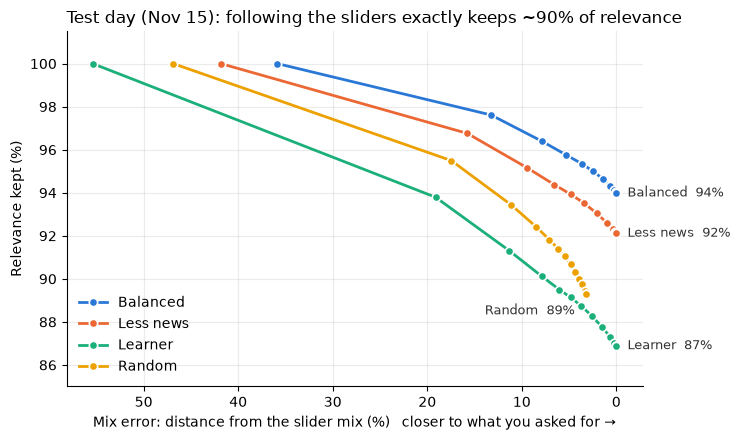

In [6]:
COLORS = {"Balanced": "#2a78d6", "Less news": "#eb6834", "Learner": "#1baf7a", "Random": "#eda100"}
LABEL_OFFSET = {"Balanced": (8, 0, "left"), "Less news": (8, 0, "left"), "Learner": (8, 0, "left"), "Random": (-8, -12, "right")}

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for name, group in sweep_test.groupby("setting", sort=False):
    ax.plot(group["mix_error_%"], group["relevance_kept_%"], color=COLORS[name], lw=2, marker="o", ms=6,
            markeredgecolor="white", markeredgewidth=1.2, label=name)
    end = group.iloc[-1]
    dx, dy, ha = LABEL_OFFSET[name]
    ax.annotate(f"{name}  {end['relevance_kept_%']:.0f}%", (end["mix_error_%"], end["relevance_kept_%"]),
                xytext=(dx, dy), textcoords="offset points", ha=ha, va="center", fontsize=9, color="#333333")
ax.set_xlabel("Mix error: distance from the slider mix (%)   closer to what you asked for →")
ax.set_ylabel("Relevance kept (%)")
ax.set_title("Test day (Nov 15): following the sliders exactly keeps ~90% of relevance", loc="left", fontsize=12)
ax.invert_xaxis()
ax.set_ylim(85, 101.5)
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig("../results/figures/chart1_relevance_vs_mix_test.png", dpi=150)
plt.show()

## Part 3: Balancer

The simulator's truth click model is fitted on Nov 15 clicks (we first check it on held-out users). The feed's own click model for the head start is the frozen one from the training days (Nov 9–13), refitted with the exact same recipe as notebook 07.

In [7]:
def shown_rows(behaviors_part, histories, rows_of):
    """Every (user, article shown, clicked) row for bucketed articles, with click-model features."""
    rows = explode_impressions(behaviors_part)
    rows["item"] = rows.news_id.map(index_of)
    rows = rows[article_buckets.cpu().numpy()[rows.item.values] >= 0].reset_index(drop=True)
    rows["hour"] = rows.time.dt.floor("h")
    hours, table = popularity_table(hourly, rows.hour.unique(), index_of)
    with torch.no_grad():
        users = user_vectors(model, histories, article_vectors)
        items = model.items(article_vectors)
        affinity = bucket_affinity(histories, article_buckets, len(BUCKETS))
        r = torch.as_tensor(rows.user_id.map(rows_of).values, device=dev)
        it = torch.as_tensor(rows.item.values, device=dev)
        hr = torch.as_tensor(rows.hour.map(hours).values, device=dev)
        score = (users[r] * items[it]).sum(1) + 0.05 * torch.as_tensor(table, device=dev)[hr, it]
        features = click_features(score[:, None], article_buckets[it][:, None], affinity[r])[:, 0, :]
    return rows, features, torch.as_tensor(rows.clicked.values, device=dev)

# Truth on Nov 15: check on held-out users, then fit on all
test_rows, test_features, test_clicked = shown_rows(test_behaviors, history, row_of)
rng = np.random.default_rng(0)
users = test_rows.user_id.unique()
fit_half = torch.as_tensor(test_rows.user_id.isin(set(rng.choice(users, len(users) // 2, replace=False))).values, device=dev)
check = ClickModel().fit(test_features[fit_half], test_clicked[fit_half])
print(f"Simulator check, AUC on held-out Nov 15 users: {auc(check.probability(test_features[~fit_half]).cpu().numpy(), test_clicked[~fit_half].cpu().numpy()):.3f}")
truth = ClickModel().fit(test_features, test_clicked)

# Frozen feed click model: same recipe as notebook 07 (train folder histories, Nov 9–13, 30% sample, seed 0)
train_row_of, train_hist = history_matrix(train_behaviors, index_of)
train_part, _ = split_by_time(train_behaviors)
_, train_features, train_clicked = shown_rows(train_part.sample(frac=0.3, random_state=0), torch.as_tensor(train_hist, device=dev), train_row_of)
feed_model = ClickModel().fit(train_features, train_clicked)

Simulator check, AUC on held-out Nov 15 users: 0.702


In [8]:
affinity = bucket_affinity(history, article_buckets, len(BUCKETS))
first_visit = test_behaviors.sort_values("time").drop_duplicates("user_id")
first_visit = first_visit[first_visit.user_id.map(lambda u: (hist[row_of[u]] >= 0).sum() >= 10)]
session_hour_row, session_table = popularity_table(hourly, first_visit.time.dt.floor("h").unique(), index_of)
session_popularity = torch.as_tensor(session_table, device=dev)

N_USERS, PAGES, MOOD, SEEDS = 2000, 30, 0.5, [0, 1, 2, 3, 4]
TARGET = [0.2, 0.2, 0.2, 0.2, 0.2]

def setup(seed):
    sample = first_visit.sample(N_USERS, random_state=seed)
    rows = torch.as_tensor(sample.user_id.map(row_of).values, device=dev)
    hours = torch.as_tensor(sample.time.dt.floor("h").map(session_hour_row).values, device=dev)
    world = World(model, article_vectors, pool_idx, pool_buckets, pool_bucket_idx,
                  session_popularity[hours][:, pool_idx], truth, BUCKETS)
    targets = np.tile(TARGET, (N_USERS, 1))
    head_start = feedforward_mix(targets, bucket_click_chance(world, history[rows], affinity[rows], feed_model))
    return world, history[rows], affinity[rows], targets, head_start

def feeds(head_start):
    return {
        "Normal feed": None,
        "Fixed quotas": lambda page, clicks, targets: targets,
        "PID only": PIDBalancer(kp=1.0, ki=0.1),
        "OwnFeed": PIDBalancer(kp=0.5, ki=0.05, start_mix=head_start),
    }

def gap_per_page(out, targets):
    read = out["expected"].cumsum(1)
    return 0.5 * np.abs(read / read.sum(2, keepdims=True) - targets[:, None, :]).sum(2).mean(0)

gaps, summary = [], []
for seed in SEEDS:
    world, start_history, taste, targets, head_start = setup(seed)
    today = shift_taste(taste, MOOD, seed)
    for name, policy in feeds(head_start).items():
        out = simulate(world, start_history, today, targets, policy, pages=PAGES, seed=seed)
        gap = gap_per_page(out, targets)
        gaps += [{"feed": name, "seed": seed, "page": p + 1, "gap": g} for p, g in enumerate(gap)]
        favorite = taste.argmax(1).cpu().numpy()
        read_mix = out["expected"].sum(1) / out["expected"].sum((1, 2))[:, None]
        summary.append({
            "feed": name, "seed": seed, "gap_after_30_pages": gap[-1],
            "favorite_topic_share_of_reading_%": 100 * read_mix[np.arange(N_USERS), favorite].mean(),
            "click_rate_%": 100 * out["clicked"].sum() / out["shown"].sum(),
        })
gaps, summary = pd.DataFrame(gaps), pd.DataFrame(summary)
balancer_test = summary.groupby("feed", sort=False).agg(["mean", "std"]).drop(columns="seed").round(3)
balancer_test

gap_after_30_pages        favorite_topic_share_of_reading_%  \
                           mean    std                              mean   
feed                                                                       
Normal feed               0.304  0.004                         40.998001   
Fixed quotas              0.221  0.003                         34.119999   
PID only                  0.153  0.002                         26.448000   
OwnFeed                   0.125  0.001                         24.818001   

                    click_rate_%         
                std         mean    std  
feed                                     
Normal feed   0.432        3.680  0.043  
Fixed quotas  0.302        3.448  0.035  
PID only      0.201        2.941  0.020  
OwnFeed       0.154        2.886  0.021

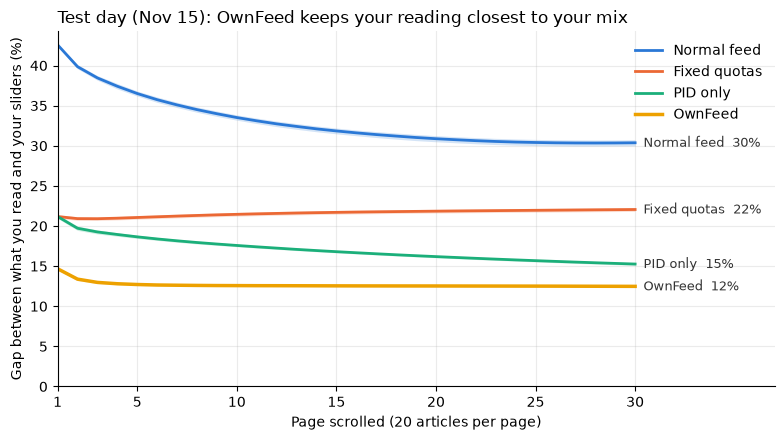

In [9]:
COLORS2 = {"Normal feed": "#2a78d6", "Fixed quotas": "#eb6834", "PID only": "#1baf7a", "OwnFeed": "#eda100"}
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, group in gaps.groupby("feed", sort=False):
    by_page = group.groupby("page").gap.agg(["mean", "std"]) * 100
    band = 2 * by_page["std"] / np.sqrt(len(SEEDS))
    ax.plot(by_page.index, by_page["mean"], color=COLORS2[name], lw=2.5 if name == "OwnFeed" else 2, label=name)
    ax.fill_between(by_page.index, by_page["mean"] - band, by_page["mean"] + band, color=COLORS2[name], alpha=0.2, lw=0)
    ax.annotate(f"{name}  {by_page['mean'].iloc[-1]:.0f}%", (PAGES, by_page["mean"].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color="#333333")
ax.set_xlabel("Page scrolled (20 articles per page)")
ax.set_ylabel("Gap between what you read and your sliders (%)")
ax.set_title("Test day (Nov 15): OwnFeed keeps your reading closest to your mix", loc="left", fontsize=12)
ax.set_xlim(1, PAGES + 7)
ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
ax.set_ylim(0, None)
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig("../results/figures/chart2_reading_gap_test.png", dpi=150)
plt.show()

## Validation vs. Test

In [12]:
val_finder = pd.read_csv("../results/finder_metrics.csv", index_col=0)
val_sweep = pd.read_csv("../results/arranger_sweep.csv")
val_balancer = pd.read_csv("../results/balancer_results.csv", header=[0, 1], index_col=0)

def at_half(sweep):
    return sweep[sweep.strictness == 0.5][["pages_exact_%", "relevance_kept_%"]].mean()

comparison = pd.DataFrame({
    "validation (Nov 14)": {
        "Finder Recall@500: Trending": val_finder.loc["trending", "recall@500"],
        "Finder Recall@500: OwnFeed": val_finder.loc["two-tower + trending (0.05)", "recall@500"],
        "Finder NDCG@10: Trending": val_finder.loc["trending", "ndcg@10"],
        "Finder NDCG@10: OwnFeed": val_finder.loc["two-tower + trending (0.05)", "ndcg@10"],
        "Arranger pages exact % (λ 0.5)": at_half(val_sweep)["pages_exact_%"],
        "Arranger relevance kept % (λ 0.5)": at_half(val_sweep)["relevance_kept_%"],
        "Reading gap: Normal feed": val_balancer.loc["Normal feed", ("gap_after_30_pages", "mean")],
        "Reading gap: Fixed quotas": val_balancer.loc["Fixed quotas", ("gap_after_30_pages", "mean")],
        "Reading gap: OwnFeed": val_balancer.loc["OwnFeed", ("gap_after_30_pages", "mean")],
        "Click rate %: Normal feed": val_balancer.loc["Normal feed", ("click_rate_%", "mean")],
        "Click rate %: OwnFeed": val_balancer.loc["OwnFeed", ("click_rate_%", "mean")],
    },
    "test (Nov 15)": {
        "Finder Recall@500: Trending": finder_test.loc["trending", "recall@500"],
        "Finder Recall@500: OwnFeed": finder_test.loc["two-tower + trending (0.05)", "recall@500"],
        "Finder NDCG@10: Trending": finder_test.loc["trending", "ndcg@10"],
        "Finder NDCG@10: OwnFeed": finder_test.loc["two-tower + trending (0.05)", "ndcg@10"],
        "Arranger pages exact % (λ 0.5)": at_half(sweep_test)["pages_exact_%"],
        "Arranger relevance kept % (λ 0.5)": at_half(sweep_test)["relevance_kept_%"],
        "Reading gap: Normal feed": balancer_test.loc["Normal feed", ("gap_after_30_pages", "mean")],
        "Reading gap: Fixed quotas": balancer_test.loc["Fixed quotas", ("gap_after_30_pages", "mean")],
        "Reading gap: OwnFeed": balancer_test.loc["OwnFeed", ("gap_after_30_pages", "mean")],
        "Click rate %: Normal feed": balancer_test.loc["Normal feed", ("click_rate_%", "mean")],
        "Click rate %: OwnFeed": balancer_test.loc["OwnFeed", ("click_rate_%", "mean")],
    },
}).round(3)
comparison

,validation (Nov 14),test (Nov 15)
Finder Recall@500: Trending,0.777,0.838
Finder Recall@500: OwnFeed,0.811,0.859
Finder NDCG@10: Trending,0.048,0.152
Finder NDCG@10: OwnFeed,0.074,0.150
Arranger pages exact % (λ 0.5),94.472,95.752
Arranger relevance kept % (λ 0.5),90.315,90.731
Reading gap: Normal feed,0.291,0.304
Reading gap: Fixed quotas,0.199,0.221
Reading gap: OwnFeed,0.109,0.125
Click rate %: Normal feed,3.781,3.680


## Takeaways (First and Only run on the test set)

- **Finder:** OwnFeed's 500 candidates catch **86% of clicks vs 84% for trending** (validation: 81% vs 78%). The main job of the finder holds up.
- **But the top-10 advantage did not hold.** NDCG@10 is a tie (0.150 vs 0.152), while on validation OwnFeed was 50% better. Nov 15 was a much more "everyone reads the same story" day: the 10 most-clicked articles got **32% of all clicks vs 21% on Nov 14**. On a day like that, "what's hot" is hard to beat at the very top, and personal taste mostly helps further down the list.
- **Arranger holds up:** At strictness 0.5, 96% of pages match the sliders exactly with 91% of relevance kept (validation: 94% and 90%).
- **Balancer holds up:** Reading gap after 30 pages is normal feed 30%, fixed quotas 22%, PID only 15%, **OwnFeed 13%** (validation: 29 / 20 / 15 / 11). Same order, slightly harder day. The simulator is even more believable on Nov 15 (AUC 0.702).
- **The price of control is the same:** Click rate 3.7% (normal feed) → 2.9% (OwnFeed).

 Nothing was tuned on Nov 15.

In [13]:
# Save the final test numbers for the README
finder_test.to_csv("../results/test_finder_metrics.csv")
sweep_test.round(4).to_csv("../results/test_arranger_sweep.csv", index=False)
balancer_test.to_csv("../results/test_balancer_results.csv")
gaps.to_csv("../results/test_balancer_gap_by_page.csv", index=False)
comparison.to_csv("../results/test_vs_validation.csv")